In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, average_precision_score
,precision_recall_curve, confusion_matrix, precision_recall_curve

sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/raw/fraudTrain.csv')

print("Shape of dataset:", df.shape)
print(df['is_fraud'].value_counts(normalize=True))
df.head()


Shape of dataset: (1296675, 23)
is_fraud
0    0.994211
1    0.005789
Name: proportion, dtype: float64


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [28]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [29]:
drop_cols = ['Unnamed: 0', 'trans_num', 'first', 'last', 'street']
df = df.drop(columns=drop_cols)

df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])

df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days // 365

def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6367 * c
    return km

df['distance_km'] = haversine_np(df['long'], df['lat'], df['merch_long'], df['merch_lat'])

df[['amt', 'age', 'hour', 'day_of_week', 'distance_km', 'is_fraud']].head()


,amt,age,hour,day_of_week,distance_km,is_fraud
0,4.97,30,0,1,78.548221,0
1,107.23,40,0,1,30.193207,0
2,220.11,56,0,1,108.138146,0
3,45.00,52,0,1,95.613163,0
4,41.96,32,0,1,77.508050,0


In [30]:
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

print("شروع داده‌ها:", df['trans_date_trans_time'].min())
print("پایان داده‌ها:", df['trans_date_trans_time'].max())


شروع داده‌ها: 2019-01-01 00:00:18
پایان داده‌ها: 2020-06-21 12:13:37


In [31]:
features = [
    'category', 'gender', 'amt', 'city_pop', 'hour',
    'day_of_week', 'age', 'distance_km'
]
target = 'is_fraud'

for col in ['category', 'gender']:
    df[col] = df[col].astype('category')

n = len(df)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

X_train = df.loc[:train_end, features]
y_train = df.loc[:train_end, target]

X_val = df.loc[train_end:val_end, features]
y_val = df.loc[train_end:val_end, target]

X_test = df.loc[val_end:, features]
y_test = df.loc[val_end:, target]

print(f"Train size: {len(X_train)} | Fraud rate: {y_train.mean():.4%}")
print(f"Val size:   {len(X_val)}   | Fraud rate: {y_val.mean():.4%}")
print(f"Test size:  {len(X_test)}  | Fraud rate: {y_test.mean():.4%}")


Train size: 1037341 | Fraud rate: 0.5753%
Val size:   129668   | Fraud rate: 0.5445%
Test size:  129668  | Fraud rate: 0.6416%


In [32]:
train_data = lgb.Dataset(X_train, label=y_train)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

scale_pos = (len(y_train) - sum(y_train)) / sum(y_train)

params = {
    'objective': 'binary',
    'metric': ['auc', 'average_precision'],
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'scale_pos_weight': scale_pos,
    'random_state': 42,
    'verbose': -1
}

model = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[train_data, val_data],
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=100)]
)


y_val_pred_proba = model.predict(X_val, num_iteration=model.best_iteration)

roc_auc = roc_auc_score(y_val, y_val_pred_proba)
pr_auc = average_precision_score(y_val, y_val_pred_proba)

print("-" * 50)
print(f"Validation ROC-AUC: {roc_auc:.4f}")
print(f"Validation PR-AUC:  {pr_auc:.4f}")
print("-" * 50)


Training until validation scores don't improve for 50 rounds
[100]	training's auc: 0.999311	training's average_precision: 0.933246	valid_1's auc: 0.997427	valid_1's average_precision: 0.908642
Early stopping, best iteration is:
[89]	training's auc: 0.999243	training's average_precision: 0.928674	valid_1's auc: 0.997469	valid_1's average_precision: 0.907198
--------------------------------------------------
Validation ROC-AUC: 0.9975
Validation PR-AUC:  0.9072
--------------------------------------------------


Optimal Threshold: 0.9778
Best Validation F1-Score: 0.8448
--------------------------------------------------
              precision    recall  f1-score   support

           0     0.9989    0.9994    0.9992    128962
           1     0.8877    0.8059    0.8448       706

    accuracy                         0.9984    129668
   macro avg     0.9433    0.9027    0.9220    129668
weighted avg     0.9983    0.9984    0.9983    129668



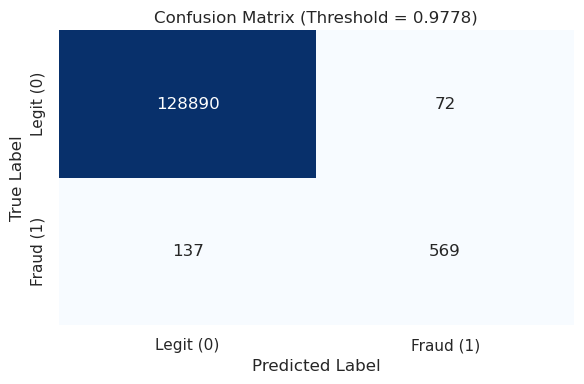

In [33]:
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_pred_proba)

f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold: {best_threshold:.4f}")
print(f"Best Validation F1-Score: {best_f1:.4f}")
print("-" * 50)

y_val_pred_binary = (y_val_pred_proba >= best_threshold).astype(int)
print(classification_report(y_val, y_val_pred_binary, digits=4))

cm = confusion_matrix(y_val, y_val_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Legit (0)', 'Fraud (1)'],
            yticklabels=['Legit (0)', 'Fraud (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix (Threshold = {best_threshold:.4f})')
plt.tight_layout()
plt.show()


/tmp/ipykernel_4562/1280016983.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df, x='Gain_Importance', y='Feature', palette='viridis')


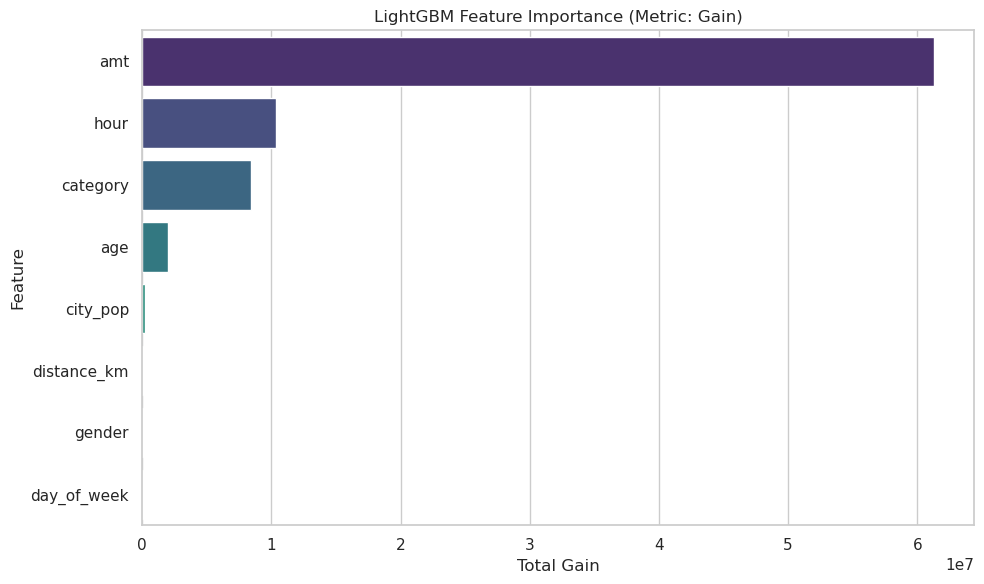

    Feature  Gain_Importance
        amt     6.131949e+07
       hour     1.035359e+07
   category     8.402036e+06
        age     2.014923e+06
   city_pop     2.443825e+05
distance_km     9.620161e+04
     gender     6.114883e+04
day_of_week     3.530893e+04


In [34]:
importance_gain = model.feature_importance(importance_type='gain')
feature_names = model.feature_name()

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Gain_Importance': importance_gain
}).sort_values('Gain_Importance', ascending=False)

# رسم نمودار
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x='Gain_Importance', y='Feature', palette='viridis')
plt.title('LightGBM Feature Importance (Metric: Gain)')
plt.xlabel('Total Gain')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print(feat_imp_df.head(10).to_string(index=False))


In [35]:
# تبدیل قطعی ستون زمان به datetime
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])

# ۱. محاسبه فاصله زمانی بین تراکنش‌های متوالی هر کارت (ثانیه)
df = df.sort_values(['cc_num', 'trans_date_trans_time']).reset_index(drop=True)

df['time_diff'] = (
    df.groupby('cc_num')['trans_date_trans_time']
    .diff()
    .dt.total_seconds()
    .fillna(999999)
)

# مرتب‌سازی زمانی کل داده‌ها
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

# ۲. محاسبه مجدد ایندکس‌های تقسیم ۸۰ / ۱۰ / ۱۰
n = len(df)
train_end_idx = int(n * 0.8)
val_end_idx = int(n * 0.9)

train_df = df.iloc[:train_end_idx].copy()
val_df = df.iloc[train_end_idx:val_end_idx].copy()
test_df = df.iloc[val_end_idx:].copy()

# ۳. محاسبه رفتار گذشته هر کارت فقط بر اساس Train (جلوگیری از Data Leakage)
user_stats = train_df.groupby('cc_num')['amt'].agg(['mean', 'std']).reset_index()
user_stats.columns = ['cc_num', 'user_amt_mean', 'user_amt_std']

train_df = train_df.merge(user_stats, on='cc_num', how='left')
val_df = val_df.merge(user_stats, on='cc_num', how='left')
test_df = test_df.merge(user_stats, on='cc_num', how='left')

# پر کردن مقادیر برای کارت‌هایی که در Train سابقه نداشتند
median_amt = train_df['amt'].median()
train_df['user_amt_mean'] = train_df['user_amt_mean'].fillna(median_amt)
val_df['user_amt_mean'] = val_df['user_amt_mean'].fillna(median_amt)
test_df['user_amt_mean'] = test_df['user_amt_mean'].fillna(median_amt)

# ۴. فیچر نسبت مبلغ جاری به میانگین تاریخی کارت
for split in [train_df, val_df, test_df]:
    split['amt_to_mean_ratio'] = split['amt'] / (split['user_amt_mean'] + 1e-5)

# مطمئن شدن از تایپ category
for col in ['category', 'gender']:
    train_df[col] = train_df[col].astype('category')
    val_df[col] = val_df[col].astype('category')
    test_df[col] = test_df[col].astype('category')

# آماده‌سازی ماتریس‌ها
features = [
    'amt', 'hour', 'category', 'age', 'city_pop',
    'distance_km', 'gender', 'day_of_week',
    'time_diff', 'amt_to_mean_ratio'
]

X_train = train_df[features]
y_train = train_df['is_fraud']

X_val = val_df[features]
y_val = val_df['is_fraud']

X_test = test_df[features]
y_test = test_df['is_fraud']

print("Ready! X_train shape:", X_train.shape)


Ready! X_train shape: (1037340, 10)


In [36]:
train_data = lgb.Dataset(X_train, label=y_train)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

model = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[train_data, val_data],
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=100)]
)

y_val_pred_proba = model.predict(X_val, num_iteration=model.best_iteration)
pr_auc = average_precision_score(y_val, y_val_pred_proba)
roc_auc = roc_auc_score(y_val, y_val_pred_proba)

print("-" * 50)
print(f"New Validation ROC-AUC: {roc_auc:.4f}")
print(f"New Validation PR-AUC:  {pr_auc:.4f}")
print("-" * 50)


Training until validation scores don't improve for 50 rounds
[100]	training's auc: 0.999468	training's average_precision: 0.924942	valid_1's auc: 0.997435	valid_1's average_precision: 0.89223
[200]	training's auc: 0.999763	training's average_precision: 0.964991	valid_1's auc: 0.998017	valid_1's average_precision: 0.92368
[300]	training's auc: 0.999877	training's average_precision: 0.979841	valid_1's auc: 0.997963	valid_1's average_precision: 0.927293
Early stopping, best iteration is:
[267]	training's auc: 0.999851	training's average_precision: 0.97638	valid_1's auc: 0.998131	valid_1's average_precision: 0.927851
--------------------------------------------------
New Validation ROC-AUC: 0.9981
New Validation PR-AUC:  0.9279
--------------------------------------------------


Optimal Threshold (Validation): 0.9788
Validation Best F1-Score:      0.8790
Validation Precision:          0.9236
Validation Recall:             0.8385
FINAL TEST SET EVALUATION:
Test PR-AUC:  0.9314
Test ROC-AUC: 0.9985

Classification Report (Test Set):
              precision    recall  f1-score   support

           0     0.9988    0.9996    0.9992    128836
           1     0.9261    0.8137    0.8663       832

    accuracy                         0.9984    129668
   macro avg     0.9625    0.9066    0.9327    129668
weighted avg     0.9983    0.9984    0.9983    129668



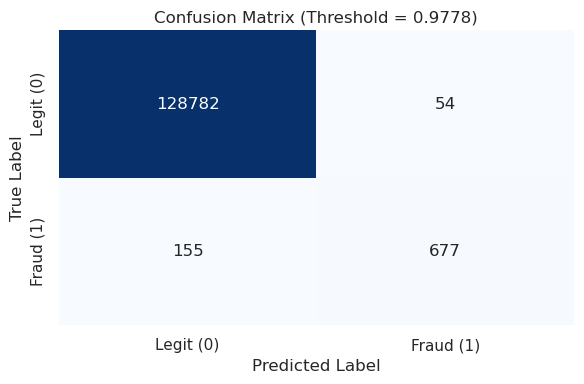

In [39]:
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_pred_proba)

f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold (Validation): {best_thresh:.4f}")
print(f"Validation Best F1-Score:      {best_f1:.4f}")
print(f"Validation Precision:          {precisions[best_idx]:.4f}")
print(f"Validation Recall:             {recalls[best_idx]:.4f}")
print("=" * 60)

y_test_pred_proba = model.predict(X_test, num_iteration=model.best_iteration)
y_test_pred_binary = (y_test_pred_proba >= best_thresh).astype(int)

print("FINAL TEST SET EVALUATION:")
print(f"Test PR-AUC:  {average_precision_score(y_test, y_test_pred_proba):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_pred_proba):.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred_binary, digits=4))

cm = confusion_matrix(y_test, y_test_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Legit (0)', 'Fraud (1)'],
            yticklabels=['Legit (0)', 'Fraud (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix (Threshold = {best_threshold:.4f})')
plt.tight_layout()
plt.show()